# Phase 3 (Track 1) — Galaxy Classification with Referenced Astronomy Packages (`astroNN` & `scikit-learn`)

This notebook documents **Classifier Track 1**, located in its own dedicated folder: `classifiers/astronn_and_astroml/`.

## Two Complementary Models in This Track
1. **Tabular Photometric Baseline (`tabular_baseline.py`, `scikit-learn` / `astroML` paradigm)**:
   - Uses 8 physical and photometric features from `data/galaxy_atlas.db` (`color_gr`, `color_ug`, `abs_mag_r`, `re_kpc`, `concentration`, `log_stellar_mass`, `log_sfr`, `redshift`) — deliberately **excluding `frac_dev_r`** so there is zero leakage.
   - Trains a balanced **Random Forest** (plus a HistGradientBoosting benchmark) against high-confidence **Galaxy Zoo** human consensus labels (`p >= 0.60`), and scores all **2,489 galaxies** into SQLite `predictions` (`model_name='rf_photometric_baseline'`).

2. **`astroNN` Galaxy10CNN (`astronn_classifier.py`, `astroNN` package)**:
   - Loads the official **Galaxy10 SDSS** dataset (`21,785` labeled `69×69` SDSS galaxy images) via `astroNN.datasets.galaxy10sdss`.
   - Implements the canonical 4-layer **`astroNN` Galaxy10CNN** architecture with **Monte Carlo Dropout** at inference time to quantify **epistemic uncertainty** ($\sigma_{\text{MC}}$).
   - Maps its 10-class Galaxy10 probability distribution into our **5 Hubble Sequence classes** (*Elliptical*, *Lenticular/Edge-on*, *Tight Spiral (Sa)*, *Medium Spiral (Sb)*, *Loose Spiral / Irregular (Sc/Irr)*) and classifies all downloaded SDSS DR17 cutouts in `data/galaxy_atlas.db` (`model_name='astronn_galaxy10_cnn'`).

In [1]:
import json
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import matplotlib.pyplot as plt
import pandas as pd
from PIL import Image

from classifiers.astronn_and_astroml.astronn_classifier import AstroNNGalaxy10Pipeline
from classifiers.astronn_and_astroml.tabular_baseline import PhotometricMorphologyClassifier
from src.config import ProjectConfig
from src.database import GalaxyDatabase

config = ProjectConfig()
ARTIFACTS_DIR = PROJECT_ROOT / "classifiers" / "astronn_and_astroml" / "artifacts"
RUN_TRAINING = False  # Set True to re-train both models from scratch

---
## Step 1: Tabular Photometric Random Forest Baseline

Test Accuracy: 0.8799 | Macro F1: 0.8661 | ROC-AUC: 0.9326
5-Fold CV Accuracy: 0.8762 +/- 0.0201

Feature Importances:


,Gini Importance
log_sfr,0.2423
concentration,0.1943
color_ug,0.1767
re_kpc,0.1315
color_gr,0.1066
log_stellar_mass,0.0629
abs_mag_r,0.0553
redshift,0.0304


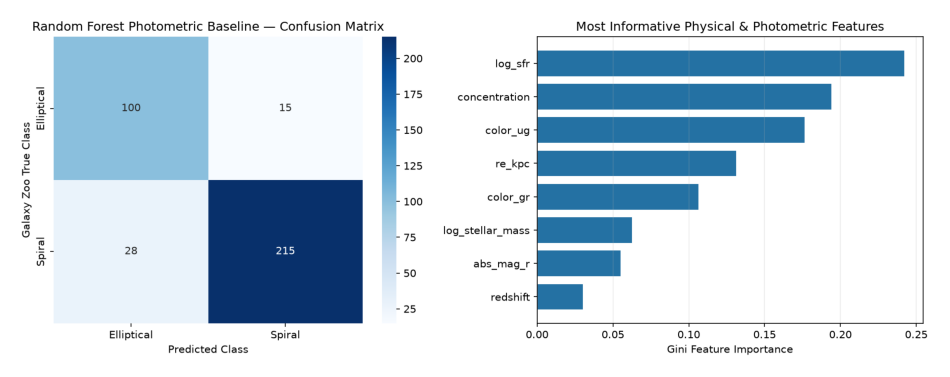

In [2]:
rf_metrics_path = ARTIFACTS_DIR / "rf_metrics.json"

if RUN_TRAINING or not rf_metrics_path.exists():
    rf_clf = PhotometricMorphologyClassifier(config)
    with GalaxyDatabase(config.db_path) as db:
        rf_metrics = rf_clf.train_and_evaluate(db)
else:
    rf_metrics = json.loads(rf_metrics_path.read_text(encoding="utf-8"))

print(f"Test Accuracy: {rf_metrics['test_accuracy']:.4f} | Macro F1: {rf_metrics['macro_f1']:.4f} | ROC-AUC: {rf_metrics['roc_auc']:.4f}")
print(f"5-Fold CV Accuracy: {rf_metrics['cv5_accuracy_mean']:.4f} +/- {rf_metrics['cv5_accuracy_std']:.4f}")
print("\nFeature Importances:")
display(pd.Series(rf_metrics["feature_importances"], name="Gini Importance").to_frame())

rf_fig = config.figures_dir / "rf_confusion_and_importance.png"
if rf_fig.exists():
    plt.figure(figsize=(12, 4.8))
    plt.imshow(Image.open(rf_fig))
    plt.axis("off")
    plt.show()

---
## Step 2: `astroNN` Galaxy10 SDSS CNN with Monte Carlo Dropout Uncertainty

5-Class Hubble Accuracy: 0.7207 | Macro F1: 0.4198
10-Class Galaxy10 Accuracy: 0.4600 | Mean MC Dropout sigma: 0.1156


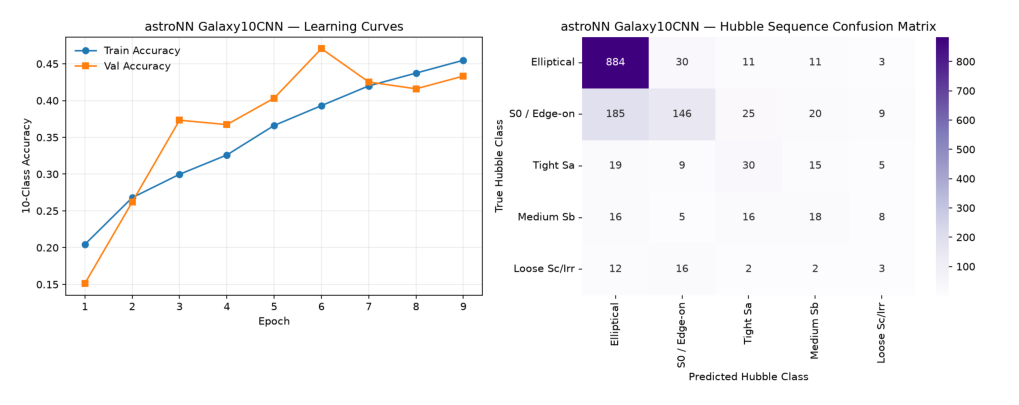

In [3]:
astronn_metrics_path = ARTIFACTS_DIR / "astronn_metrics.json"

if RUN_TRAINING or not astronn_metrics_path.exists():
    pipe = AstroNNGalaxy10Pipeline(config)
    astronn_metrics = pipe.train_and_evaluate(epochs=10, max_samples=10000)
    with GalaxyDatabase(config.db_path) as db:
        n_pred = pipe.predict_catalog_cutouts(db)
        astronn_metrics["n_catalog_predicted"] = n_pred
else:
    astronn_metrics = json.loads(astronn_metrics_path.read_text(encoding="utf-8"))

print(f"5-Class Hubble Accuracy: {astronn_metrics['test_accuracy']:.4f} | Macro F1: {astronn_metrics['macro_f1']:.4f}")
print(f"10-Class Galaxy10 Accuracy: {astronn_metrics['test_accuracy_10class']:.4f} | Mean MC Dropout sigma: {astronn_metrics['mean_mc_epistemic_std']:.4f}")

astro_fig = config.figures_dir / "astronn_cnn_evaluation.png"
if astro_fig.exists():
    plt.figure(figsize=(13, 5.0))
    plt.imshow(Image.open(astro_fig))
    plt.axis("off")
    plt.show()

---
## Step 3: Inspect Stored Track 1 Predictions in SQLite

In [4]:
with GalaxyDatabase(config.db_path) as db:
    pred_summary = db.get_predictions_summary()
display(pred_summary)

,model_name,model_version,predicted_class,galaxy_count,avg_confidence
0,astronn_galaxy10_cnn,v1,Lenticular/Edge-on,226,0.654033
1,astronn_galaxy10_cnn,v1,Elliptical,50,0.480262
2,astronn_galaxy10_cnn,v1,Loose Spiral / Irregular (Sc/Irr),7,0.391200
3,astronn_galaxy10_cnn,v1,Tight Spiral (Sa),1,0.365100
4,rf_photometric_baseline,v1,Spiral,1539,0.874261
5,rf_photometric_baseline,v1,Elliptical,950,0.798941
6,tensorflow_hubble_cnn,v1,Loose Spiral / Irregular (Sc/Irr),202,0.656042
7,tensorflow_hubble_cnn,v1,Lenticular/Edge-on,43,0.650695
8,tensorflow_hubble_cnn,v1,Elliptical,19,0.720637
9,tensorflow_hubble_cnn,v1,Medium Spiral (Sb),10,0.413650
